 ## Assinmnet 4: 
* Name: <b>Samarth waghrulkar</b><br>
* Roll: <b>124B1F108</b>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:

df = pd.read_csv('C:/Users/sam/Downloads/uber.csv')
df = df.drop(columns=['Unnamed: 0', 'key'], errors='ignore')
df.head()

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [3]:
print(df.shape)
display(df.head())
display(df.describe())
print(df.isna().sum())

(200000, 7)


,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [4]:
df=df.dropna().drop_duplicates()

df=df[(df.fare_amount>0)&(df.fare_amount<100)]
df=df[(df.passenger_count>=1)&(df.passenger_count<=6)]

for c in ['pickup_latitude','dropoff_latitude']:
    df=df[df[c].between(-90,90)]
for c in ['pickup_longitude','dropoff_longitude']:
    df=df[df[c].between(-180,180)]

In [5]:
# Datetime features
df['pickup_datetime']=pd.to_datetime(df['pickup_datetime'])
df['year']=df['pickup_datetime'].dt.year
df['month']=df['pickup_datetime'].dt.month
df['day']=df['pickup_datetime'].dt.day
df['hour']=df['pickup_datetime'].dt.hour
df['weekday']=df['pickup_datetime'].dt.weekday

In [6]:
# Haversine distance (km)
R=6371.0
lat1=np.radians(df['pickup_latitude'])
lon1=np.radians(df['pickup_longitude'])
lat2=np.radians(df['dropoff_latitude'])
lon2=np.radians(df['dropoff_longitude'])

dlat=lat2-lat1
dlon=lon2-lon1
a=np.sin(dlat/2)**2+np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
c=2*np.arctan2(np.sqrt(a),np.sqrt(1-a))
df['distance_km']=R*c

# Remove unrealistic trips
df=df[(df.distance_km>0.1)&(df.distance_km<100)]

# Drop raw columns no longer needed now that distance_km and datetime parts are extracted
df = df.drop(columns=['pickup_datetime','pickup_latitude','pickup_longitude',
                       'dropoff_latitude','dropoff_longitude'], errors='ignore')

In [7]:
# IQR outlier removal for fare and distance
for col in ['fare_amount','distance_km']:
    q1=df[col].quantile(0.25)
    q3=df[col].quantile(0.75)
    iqr=q3-q1
    low=q1-1.5*iqr
    high=q3+1.5*iqr
    df=df[(df[col]>=low)&(df[col]<=high)]

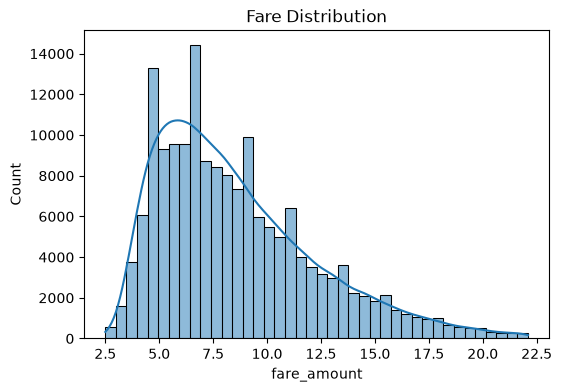

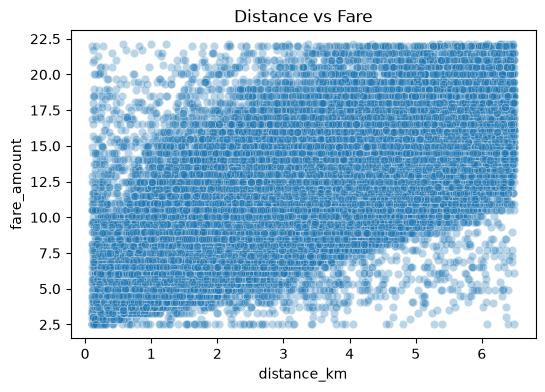

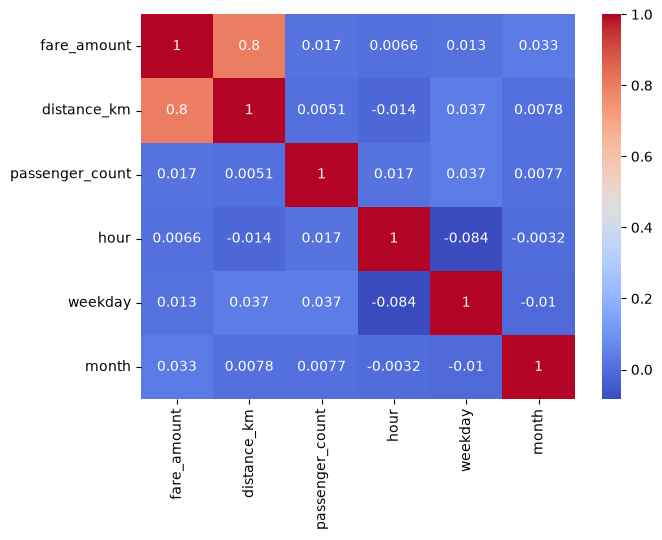

Distance-Fare correlation: 0.7986381834176304


In [8]:
# EDA
plt.figure(figsize=(6,4))
sns.histplot(df['fare_amount'],bins=40,kde=True)
plt.title('Fare Distribution')
plt.show()

plt.figure(figsize=(6,4))
sns.scatterplot(data=df,x='distance_km',y='fare_amount',alpha=0.3)
plt.title('Distance vs Fare')
plt.show()

corr=df[['fare_amount','distance_km','passenger_count','hour','weekday','month']].corr()
plt.figure(figsize=(7,5))
sns.heatmap(corr,annot=True,cmap='coolwarm')
plt.show()

print("Distance-Fare correlation:",df['distance_km'].corr(df['fare_amount']))

In [9]:
# Features
X=df[['distance_km','passenger_count','year','month','day','hour','weekday']]
y=df['fare_amount']

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

scaler=StandardScaler()
X_train_s=scaler.fit_transform(X_train)
X_test_s=scaler.transform(X_test)

In [10]:
# Linear Regression without PCA
lr=LinearRegression()
lr.fit(X_train_s,y_train)
pred=lr.predict(X_test_s)

mae=mean_absolute_error(y_test,pred)
rmse=np.sqrt(mean_squared_error(y_test,pred))
r2=r2_score(y_test,pred)

print('Without PCA')
print('MAE:',mae)
print('RMSE:',rmse)
print('R2:',r2)

Without PCA
MAE: 1.522815111603606
RMSE: 2.1431502261466235
R2: 0.6682735962984745


Components retained: 7
Explained variance: [0.15998285 0.15756389 0.14479154 0.14335873 0.14080502 0.12818555
 0.12531242]


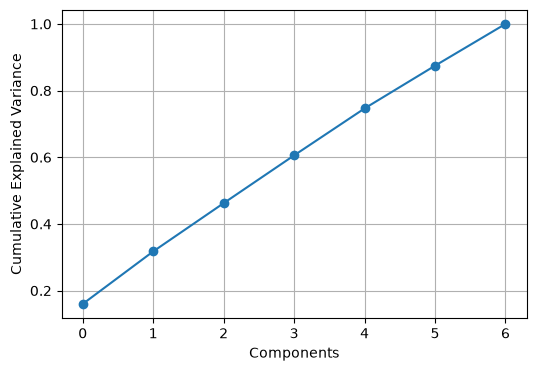

In [11]:
# PCA
pca=PCA(n_components=0.95)
X_train_p=pca.fit_transform(X_train_s)
X_test_p=pca.transform(X_test_s)

print('Components retained:',pca.n_components_)
print('Explained variance:',pca.explained_variance_ratio_)

plt.figure(figsize=(6,4))
plt.plot(np.cumsum(pca.explained_variance_ratio_),marker='o')
plt.xlabel('Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid(True)
plt.show()

In [12]:
# Linear Regression with PCA
lr2=LinearRegression()
lr2.fit(X_train_p,y_train)
pred2=lr2.predict(X_test_p)

mae2=mean_absolute_error(y_test,pred2)
rmse2=np.sqrt(mean_squared_error(y_test,pred2))
r22=r2_score(y_test,pred2)

comparison=pd.DataFrame({
    'Metric':['MAE','RMSE','R2'],
    'Without PCA':[mae,rmse,r2],
    'With PCA':[mae2,rmse2,r22]
})
display(comparison)

,Metric,Without PCA,With PCA
0,MAE,1.522815,1.522815
1,RMSE,2.143150,2.143150
2,R2,0.668274,0.668274
